# Librerias

In [33]:
import sys
import os
import datetime

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, PReLU, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from keras.metrics import Precision, Recall, AUC
import keras

from src.Modelo_ANN import Binary_Model

# Carga de subsets

In [34]:
subsets = ['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set']

paths = ['../data/partitions/X_train_scaled.csv',
         '../data/partitions/y_train.csv',
         '../data/partitions/X_test_scaled.csv',
         '../data/partitions/y_test.csv',
         '../data/partitions/validation_set.parquet']



In [35]:
subsets

['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set']

In [36]:
binary_model = Binary_Model(*subsets, paths)

In [37]:
binary_model.set_partitions()

In [38]:
binary_model.partitions.keys()

dict_keys(['X_train_scaled', 'y_train', 'X_test_scaled', 'y_test', 'validation_set'])

In [39]:
# Ejecuta esto en una celda para inspeccionar los tamaños
print("Dimensiones de X_train:", binary_model.partitions[binary_model.x_train_file_name].shape)
print("Dimensiones de Y_train:", binary_model.partitions[binary_model.y_train_file_name].shape)
print("Dimensiones de X_test:", binary_model.partitions[binary_model.x_test_file_name].shape)
print("Dimensiones de Y_test:", binary_model.partitions[binary_model.y_test_file_name].shape)


Dimensiones de X_train: (5616, 20)
Dimensiones de Y_train: (5616, 1)
Dimensiones de X_test: (1404, 20)
Dimensiones de Y_test: (1404, 1)


# Carga de scaler

In [40]:
binary_model.save_load_scaler('../models/scaler.pkl', load= True)

# Configuracion de flujo y entrenamineto

In [41]:
tf.config.experimental.enable_op_determinism()

beta = 0.999# Hiperparámetro a ajustar
pesos_dict = {}
for c in np.unique(binary_model.partitions[binary_model.y_train_file_name]):
    n_j = np.sum(binary_model.partitions[binary_model.y_train_file_name].to_numpy() == c)
    pesos_dict[c] = (1.0 - beta) / (1.0 - np.power(beta, n_j))

binary_model.preparar_experimento(
    45
                                  
).model_flow_settings(
    capas = 6, 
    fun_act = 'PReLU',
    loss = 'binary_crossentropy',
    optimizer = 'adam',
    n_output = 1,
    dropout = 0.5,
    fun_out= 'sigmoid',
    leakyrelu_negative_slope = None,
    n_down = 0.5
).start_training(
    epochs = 600,
    w_balance= True,
    w_dict = None,
    batch_size = 800, 
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=25,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../checkpoints/models/binary_model.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)

Epoch 1/600


/home/hadoop/CUC/IA_Aplicada/Proyecto_Abandono_Clientes/.IA_Abandono_wsl/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
E0000 00:00:1791836793.889348 2186371 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMap

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - loss: 0.6931 - prc: 0.2719 - val_loss: 0.6926 - val_prc: 0.3290
Epoch 2/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6923 - prc: 0.2792 - val_loss: 0.6926 - val_prc: 0.3894
Epoch 3/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.6921 - prc: 0.2756 - val_loss: 0.6934 - val_prc: 0.4064
Epoch 4/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6902 - prc: 0.2977 - val_loss: 0.6891 - val_prc: 0.4235
Epoch 5/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6889 - prc: 0.2981 - val_loss: 0.6815 - val_prc: 0.4450
Epoch 6/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6871 - prc: 0.3069 - val_loss: 0.6737 - val_prc: 0.4858
Epoch 7/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6845 - prc: 0.3162 - val_loss: 0.6650 - val_prc: 0.5004
Epoch 8/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6816 - prc: 0.3393 - val_loss: 0.6486 - val_prc: 0.5038
Epoch 9/600
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.6738 - prc: 0.3746 - val

<Axes: >

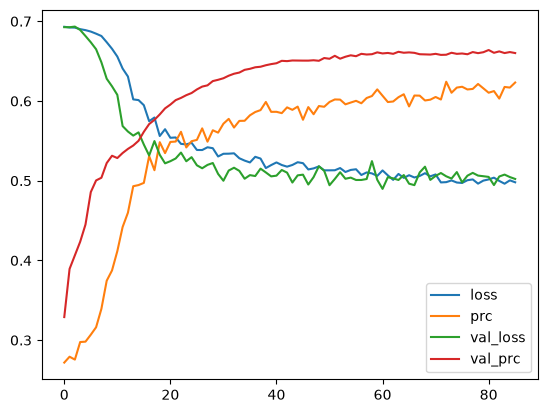

In [42]:
losses = pd.DataFrame(binary_model.model.history.history)

losses.plot()

# Evaluacion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Reporte de clasificacion:
               precision    recall  f1-score   support

         0.0       0.70      1.00      0.82        14
         1.0       1.00      0.33      0.50         9

    accuracy                           0.74        23
   macro avg       0.85      0.67      0.66        23
weighted avg       0.82      0.74      0.70        23
 

Matriz de confucion:
                        No abandona(predict) (0)  Abandona(predict) (1)
No abandona(real) (0)                        14                      0
Abandona(real) (1)                            6                      3
Reporte de clasificacion:
               precision    recall  f1-score   support

         0.0       0.70      1.00      0.82        14
         1.0       1.00      0.33      0.50         9

    accuracy                           0.74        23
   macro avg       0.85      0.67      0.66        23
weighted avg       0.82      0.74      0.70        23
 

Matriz de confu

E0000 00:00:1791836806.958083 2186371 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


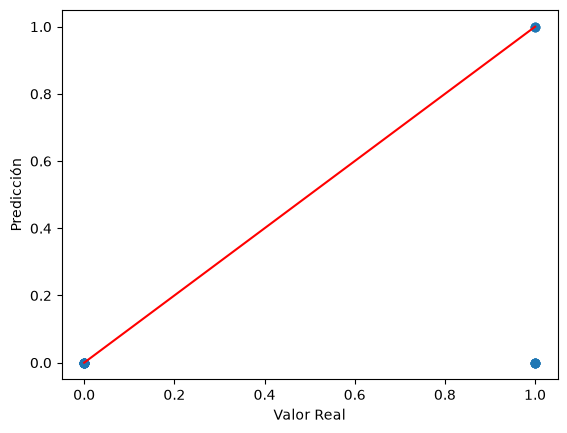

In [43]:
binary_model.make_prediction(target= 'Abandono', eval= True)

In [46]:
t_data = pd.concat(
    [
        binary_model.partitions[binary_model.x_test_file_name],
        binary_model.partitions[binary_model.y_test_file_name]
    ], axis = 1
)   


val_data = pd.concat(
    [
        binary_model.partitions[binary_model.val_file_name],
        t_data
    ], axis = 0
)


val_data

,Adulto_Mayor,Pareja,Dependientes,Antiguedad(Meses),Servicio_Telefono,Lineas_Multiples,Internet_DSL,Internet_Fiber optic,Seguridad_Online,Copia_Seguridad_Online,...,10,11,12,13,14,15,16,17,18,19
0,0.0,0.0,1.0,31.0,1.0,1.0,1.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.0,0.0,0.0,16.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.0,0.0,0.0,10.0,1.0,0.0,0.0,1.0,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.0,1.0,0.0,12.0,1.0,0.0,0.0,1.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1399,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.747012
1400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,1.0,1.0,1.0,0.5,1.0,0.0,0.0,1.0,0.921813
1401,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.017430
1402,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,1.0,1.0,0.5,1.0,0.0,0.0,0.0,0.870020


In [45]:
# Una vez terminado model.fit(...)
#nombre_archivo = '../models/binary_model_74_accur.keras'

# Guardar el modelo completo
#binary_model.model.save(nombre_archivo)
#print(f"Modelo guardado exitosamente en: {nombre_archivo}")
